# Solutions to the exercises of Chapter 10

Sample solutions for [Chapter 10, Boiling and condensation](../../notebooks/part2_convection/10_boiling_condensation.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import phase_change, properties
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import phase_change, properties
from engtransport.constants import SIGMA_SB
from engtransport.plotting import use_style

use_style()

## Exercise 1. Vertical or horizontal?

In [2]:
sat = properties.saturated_water(373.15)
T_w, D, L = 273.15 + 90.0, 0.025, 2.0
dT = 373.15 - T_w
film = properties.water_properties(373.15 - dT / 2)
Ja = film["cp"] * dT / sat["h_fg"]
h_fgp = sat["h_fg"] * phase_change.film_condensation_subcooling(Ja)["ratio"]
A = math.pi * D * L
for geometry, length in (("vertical", L), ("tube", D)):
    h = phase_change.h_film_condensation(film["rho"], sat["rho_v"], film["k"], film["mu"], h_fgp, dT, length, geometry)
    m_dot = h * A * dT / h_fgp
    extra = ""
    if geometry == "vertical":
        extra = f"; film Reynolds number at the bottom 4 Gamma/mu = {4 * m_dot / (math.pi * D) / film['mu']:.0f}"
    print(f"{'vertical' if geometry == 'vertical' else 'horizontal'}: h = {h:.0f} W/(m2 K), {3600 * m_dot:.1f} kg/h condensed{extra}")

vertical: h = 5396 W/(m2 K), 13.4 kg/h condensed; film Reynolds number at the bottom 4 Gamma/mu = 636
horizontal: h = 12461 W/(m2 K), 30.8 kg/h condensed


Horizontal, the tube condenses 2.3 times as much: its film runs only half the
circumference, about 40 mm, before it drips off, against 2 m down the vertical tube. The
film Reynolds number at the bottom of the vertical tube is about 640: still laminar, but
wavy, so Nusselt's value for it is somewhat pessimistic. The advantage of the horizontal
tube stays large.

## Exercise 2. Pressure and the critical heat flux

In [3]:
for T_C in (100.0, 150.0, 200.0):
    s = properties.saturated_water(273.15 + T_C)
    q = phase_change.zuber_critical_heat_flux(s["rho"], s["rho_v"], s["h_fg"], s["sigma"])
    print(f"{T_C:.0f} C ({s['p_sat'] / 1e5:5.2f} bar): rho_v = {s['rho_v']:6.3f} kg/m3, h_fg = {s['h_fg'] / 1e6:.3f} MJ/kg,"
          f" sigma = {1e3 * s['sigma']:.1f} mN/m: q_max = {q / 1e6:.2f} MW/m2")

100 C ( 1.01 bar): rho_v =  0.598 kg/m3, h_fg = 2.256 MJ/kg, sigma = 58.9 mN/m: q_max = 1.26 MW/m2
150 C ( 4.76 bar): rho_v =  2.548 kg/m3, h_fg = 2.114 MJ/kg, sigma = 48.7 mN/m: q_max = 2.30 MW/m2
200 C (15.55 bar): rho_v =  7.859 kg/m3, h_fg = 1.940 MJ/kg, sigma = 37.7 mN/m: q_max = 3.42 MW/m2


The critical heat flux rises from 1.26 MW/m² at 1 bar to 3.4 MW/m² at 15.5 bar. In
Eq. (10.8) $q_{max} \propto \rho_v^{1/2} h_{fg}\,\sigma^{1/4}$ roughly, and the vapour
density rises thirteenfold over this range while the latent heat and surface tension fall
only slowly. Denser vapour carries more latent heat away through the same vapour
columns. At still higher pressures the latent heat and surface tension fall towards zero
at the critical point, and the peak flux passes through a maximum near a third of the
critical pressure.

## Exercise 3. Quenching again

In [4]:
D_bar, T_s, eps = 0.050, 273.15 + 700.0, 0.8
dT_e = T_s - 373.15
vap = properties.steam_properties(373.15 + dT_e / 2)
h_conv = phase_change.bromley_film_boiling(D_bar, dT_e, sat["rho"], vap["rho"], vap["k"], vap["mu"], vap["cp"], sat["h_fg"])
h_rad = eps * SIGMA_SB * (T_s**4 - 373.15**4) / dT_e
h = h_conv + 0.75 * h_rad
q_min = phase_change.minimum_heat_flux(sat["rho"], sat["rho_v"], sat["h_fg"], sat["sigma"])
print(f"film boiling at 700 C: h_conv = {h_conv:.0f}, h_rad = {h_rad:.0f}, h = {h:.0f} W/(m2 K); flux {h * dT_e / 1e3:.0f} kW/m2")
print(f"minimum heat flux {q_min / 1e3:.0f} kW/m2")

film boiling at 700 C: h_conv = 129, h_rad = 66, h = 179 W/(m2 K); flux 107 kW/m2
minimum heat flux 19 kW/m2


In saturated water the vapour film gives only about 180 W/(m² K) at 700 °C, more than a
quarter of it by radiation: five to six times less than the 1000 W/(m² K) assumed in
Chapter 5. The quench
bath of Chapter 5 was at 30 °C, 70 K below boiling. Subcooled water condenses much of the
vapour at the edge of the film, so the film is thinner and the coefficient several times
larger than in saturated water. In practice quench baths are agitated and subcooled for
exactly this reason, and the film-boiling stage is short. The heat flux, 107 kW/m², is
well above the minimum of 19 kW/m², so film boiling persists until the surface has
cooled a good deal further.

## Exercise 4. Limescale in a kettle

0.5 mm of scale: sheath at 282 C (scale surface at 113 C)
the sheath reaches 400 C under 0.82 mm of scale


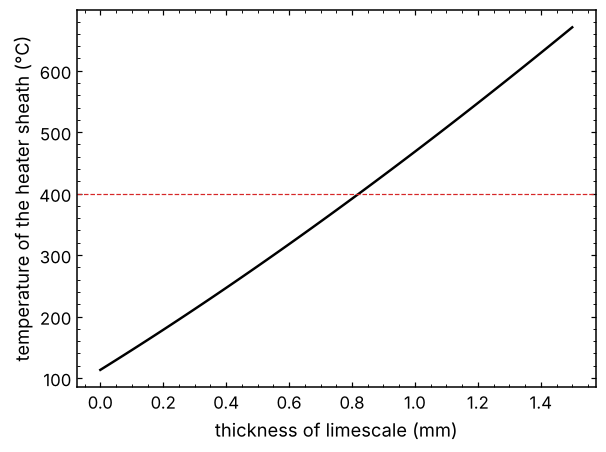

In [5]:
q_el = 2000.0 / (math.pi * 0.008 * 0.25)
dT_boil = brentq(lambda d: phase_change.rohsenow_heat_flux(d, sat["mu"], sat["h_fg"], sat["rho"], sat["rho_v"], sat["sigma"],
                                                          sat["cp"], sat["Pr"]) - q_el, 0.1, 100.0)
k_scale = 1.0
ts = np.linspace(0.0, 1.5e-3, 61)
r_o = 0.004
T_sheath = 100.0 + dT_boil + q_el * r_o * np.log((r_o + ts) / r_o) / k_scale * (r_o + ts) / r_o
for t in (0.5e-3,):
    i = int(np.argmin(np.abs(ts - t)))
    print(f"{1000 * t:.1f} mm of scale: sheath at {T_sheath[i]:.0f} C (scale surface at {100 + dT_boil:.0f} C)")
t_max = brentq(lambda t: 100.0 + dT_boil + q_el * r_o * math.log((r_o + t) / r_o) / k_scale * (r_o + t) / r_o - 400.0, 1e-5, 5e-3)
print(f"the sheath reaches 400 C under {1000 * t_max:.2f} mm of scale")

fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(1000 * ts, T_sheath, "k-")
ax.axhline(400.0, color="C3", ls="--", lw=0.8)
ax.set_xlabel("thickness of limescale (mm)")
ax.set_ylabel("temperature of the heater sheath (°C)")
plt.show()

**Figure S10.1.** Temperature of the heater sheath at 2 kW against the thickness of the
limescale on it (scale conductivity 1 W/(m K)).

The scale grows outwards on the 8 mm sheath, so the heat flux at its outer surface is
slightly smaller, and the boiling there stays at about 113 °C. The heat still has to cross
the scale by conduction: 0.5 mm of it adds about 170 K, putting the sheath at about
280 °C instead of 113 °C. At about 0.8 mm the sheath reaches 400 °C, where its insulation and
heating wire age quickly. The heat flux is fixed by the electric power, so the scale
cannot reduce the heat delivered; it raises the temperature instead, exactly as the vapour
film does at the boiling crisis. Descaling is maintenance of the heater, not of the water.